### Bradley–Terry Score-Recovery Experiments


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter
import pandas as pd
SEED=20260831
rng=np.random.default_rng(SEED)

In [5]:
items=np.array(["car","taxi","bus"])
true_scores=np.array([0.8,0.1,-0.9])
number_of_items=len(items)
number_of_comparisons=30
def sigmoid(x):
    probability=1/(1+np.exp(-x))
    return probability

In [11]:
def bt_probability(item_i,item_j,scores):
    score_difference=scores[item_i] - scores[item_j]
    probability_i_wins=sigmoid(score_difference)
    return probability_i_wins
winners=[]
loosers=[]
for comparison in range(number_of_comparisons):
    item_i,item_j=rng.choice(number_of_items, size=2, replace=False)
    probability_i_wins=bt_probability(item_i, item_j,true_scores)
    random_number=rng.random()
    if random_number<probability_i_wins:
        winner=item_i
        looser=item_j
    else:
        winner=item_j
        looser=item_i
    winners.append(winner)
    loosers.append(looser)
for comparison in range(10):
    winner=winners[comparison]
    looser=loosers[comparison]
    print(comparison, ":",items[winner], "beats", items[looser])

0 : taxi beats bus
1 : car beats taxi
2 : car beats taxi
3 : taxi beats car
4 : taxi beats car
5 : bus beats taxi
6 : taxi beats bus
7 : car beats taxi
8 : taxi beats bus
9 : taxi beats car


In [23]:
import pandas as pd
comparison_data = pd.DataFrame({"winner_index": winners, "loser_index": loosers, "winner": [items[index] for index in winners], "looser": [items[index] for index in loosers]})
comparison_data.head(21)

,winner_index,loser_index,winner,looser
0,1,2,taxi,bus
1,0,1,car,taxi
2,0,1,car,taxi
3,1,0,taxi,car
4,1,0,taxi,car
5,2,1,bus,taxi
6,1,2,taxi,bus
7,0,1,car,taxi
8,1,2,taxi,bus
9,1,0,taxi,car


In [22]:
def negative_log_likelihood(scores, winners, loosers):
    total_nll=0
    for winner, looser in zip(winners,loosers):
        probability=bt_probability(winner, looser, scores)
        total_nll=total_nll-np.log(probability)
    average_nll=total_nll/len(winners)
    return average_nll

initial_scores = np.zeros(number_of_items)
initial_nll = negative_log_likelihood(initial_scores,winners,loosers)
true_nll = negative_log_likelihood(true_scores,winners,loosers)
print("NLL using equal scores:", initial_nll)
print("NLL using true scores:", true_nll)

NLL using equal scores: 0.693147180559945
NLL using true scores: 0.6289562997887526


In [30]:
def bt_gradient(scores, winners, loosers):
    gradient = np.zeros_like(scores)
    for winner, looser in zip(winners, loosers):
        probability = bt_probability(winner,looser,scores)
        gradient[winner] += probability - 1
        gradient[looser] += 1 - probability
    average_gradient = gradient / len(winners)
    return average_gradient
initial_gradient = bt_gradient(initial_scores,winners,loosers)
print("Initial scores:", initial_scores)
print("Initial gradient:", initial_gradient)

Initial scores: [0. 0. 0.]
Initial gradient: [-0.13333333  0.01666667  0.11666667]


In [31]:
learning_rate = 0.1
number_of_iterations = 1000
estimated_scores = np.zeros(number_of_items)
nll_history = []
for iteration in range(number_of_iterations):
    gradient = bt_gradient(estimated_scores,winners,loosers)
    estimated_scores = (estimated_scores- learning_rate * gradient)
    estimated_scores = (estimated_scores- np.mean(estimated_scores))
    current_nll = negative_log_likelihood(estimated_scores,winners,loosers)
    nll_history.append(current_nll)
print("First five NLL values:", nll_history[:5])
print("Last five NLL values:", nll_history[-5:])
print("True scores:", true_scores)
print("Estimated scores:", estimated_scores)
print("Initial NLL:", initial_nll)
print("Final NLL:", nll_history[-1])

First five NLL values: [0.6900140549677359, 0.6870122585719981, 0.6841362542447738, 0.6813807166495515, 0.6787405275506853]
Last five NLL values: [0.6152145423588049, 0.6152145423588048, 0.6152145423588048, 0.6152145423588049, 0.6152145423588048]
True scores: [ 0.8  0.1 -0.9]
Estimated scores: [ 0.68483709 -0.08411659 -0.6007205 ]
Initial NLL: 0.693147180559945
Final NLL: 0.6152145423588048


In [32]:
score_difference = (estimated_scores - true_scores)
squared_difference = score_difference ** 2
mean_squared_error = np.mean(squared_difference)
recovery_error = np.sqrt(mean_squared_error)
print("Score differences:", score_difference)
print("Squared differences:", squared_difference)
print("Recovery error:", recovery_error)

Score differences: [-0.11516291 -0.18411659  0.2992795 ]
Squared differences: [0.0132625  0.03389892 0.08956822]
Recovery error: 0.21348664072755272


Now, repeating the experiment for different number of comparisons

In [36]:
def generate_comparison_data(true_scores,number_of_comparisons,rng):
    number_of_items = len(true_scores)
    winners = []
    loosers = []
    for comparison in range(number_of_comparisons):
        item_i, item_j = rng.choice(number_of_items,size=2,replace=False)
        probability_i_wins = bt_probability(item_i,item_j,true_scores)
        random_number = rng.random()
        if random_number < probability_i_wins:
            winner = item_i
            looser = item_j
        else:
            winner = item_j
            looser = item_i
        winners.append(winner)
        loosers.append(looser)
    return winners, loosers
test_rng = np.random.default_rng(SEED)
test_winners, test_loosers = generate_comparison_data(true_scores,30,test_rng)
print("First five winners:", test_winners[:5])
print("First five loosers:", test_loosers[:5])

First five winners: [2, 1, 0, 1, 1]
First five loosers: [0, 2, 2, 2, 2]


In [37]:
generate_comparison_data(true_scores, 30, rng)

([2,
  1,
  0,
  1,
  1,
  0,
  0,
  1,
  0,
  1,
  0,
  0,
  0,
  1,
  1,
  0,
  2,
  1,
  2,
  2,
  0,
  0,
  0,
  1,
  1,
  1,
  0,
  1,
  1,
  0],
 [0,
  2,
  2,
  2,
  2,
  2,
  1,
  0,
  2,
  2,
  1,
  1,
  2,
  0,
  2,
  2,
  1,
  2,
  1,
  0,
  1,
  1,
  2,
  2,
  2,
  2,
  1,
  2,
  2,
  2])

In [40]:
def estimate_bt_scores(number_of_items,winners,loosers,learning_rate=0.1,number_of_iterations=1000):
    estimated_scores=np.zeros(number_of_items)
    nll_history=[]
    for iteration in range(number_of_iterations):
        gradient=bt_gradient(estimated_scores,winners,loosers)
        estimated_scores=estimated_scores-learning_rate*gradient
        estimated_scores=estimated_scores-np.mean(estimated_scores)
        current_nll=negative_log_likelihood(estimated_scores,winners,loosers)
        nll_history.append(current_nll)
    return estimated_scores,nll_history
test_estimated_scores,test_nll_history=estimate_bt_scores(number_of_items,test_winners,test_loosers)
test_recovery_error=np.sqrt(np.mean((test_estimated_scores-true_scores)**2))
print("True scores:",true_scores)
print("Estimated scores:",test_estimated_scores)
print("Recovery error:",test_recovery_error)
print("Final NLL:",test_nll_history[-1])

True scores: [ 0.8  0.1 -0.9]
Estimated scores: [ 0.8331208   0.22521619 -1.05833698]
Recovery error: 0.1181054357040233
Final NLL: 0.5162367391182489


Comparisons: 30 Recovery error: 0.1181
Comparisons: 50 Recovery error: 0.12
Comparisons: 100 Recovery error: 0.2679
Comparisons: 300 Recovery error: 0.0562
Comparisons: 500 Recovery error: 0.0486
Comparisons: 1000 Recovery error: 0.0895


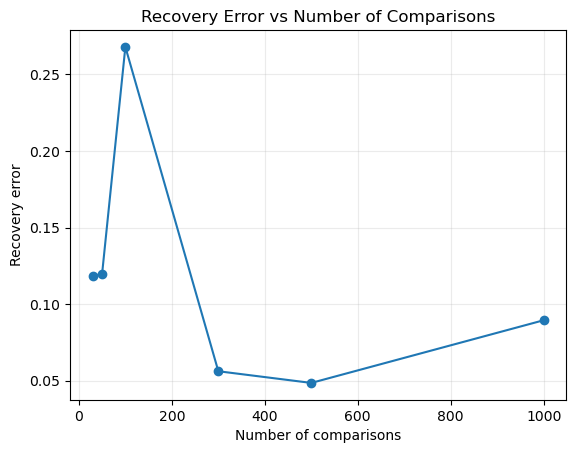

In [ ]:
comparison_counts=[30,50,100,300,500,1000]
recovery_errors=[]
experiment_rng=np.random.default_rng(SEED)
#total_start_time=perf_counter()
for number_of_comparisons in comparison_counts:
    start_time=perf_counter()
    experiment_winners,experiment_loosers=generate_comparison_data(true_scores,number_of_comparisons,experiment_rng)
    experiment_scores,nll_history=estimate_bt_scores(number_of_items,experiment_winners,experiment_loosers)
    error=np.sqrt(np.mean((experiment_scores-true_scores)**2))
    recovery_errors.append(error)
    print("Comparisons:",number_of_comparisons,"Recovery error:",round(error,4))
plt.plot(comparison_counts,recovery_errors,marker="o")
plt.xlabel("Number of comparisons")
plt.ylabel("Recovery error")
plt.title("Recovery Error vs Number of Comparisons")
plt.grid(alpha=0.25)
plt.show()

In [44]:
number_of_runs=10
mean_recovery_errors=[]
std_recovery_errors=[]
# start_time=perf_counter()
for number_of_comparisons in comparison_counts:
    run_errors=[]
    for run in range(number_of_runs):
        run_rng=np.random.default_rng(SEED+run)
        run_winners,run_loosers=generate_comparison_data(
            true_scores,
            number_of_comparisons,
            run_rng)
        run_scores,nll_history=estimate_bt_scores(
            number_of_items,
            run_winners,
            run_loosers)
        run_error=np.sqrt(np.mean((run_scores-true_scores)**2))
        run_errors.append(run_error)
    mean_error=np.mean(run_errors)
    std_error=np.std(run_errors)
    mean_recovery_errors.append(mean_error)
    std_recovery_errors.append(std_error)
    print(
        "Comparisons:",number_of_comparisons,
        "Mean error:",round(mean_error,4),
        "Standard deviation:",round(std_error,4)
    )

Comparisons: 30 Mean error: 0.2441 Standard deviation: 0.0981
Comparisons: 50 Mean error: 0.204 Standard deviation: 0.1003
Comparisons: 100 Mean error: 0.1309 Standard deviation: 0.0458
Comparisons: 300 Mean error: 0.0997 Standard deviation: 0.0505
Comparisons: 500 Mean error: 0.0721 Standard deviation: 0.0279
Comparisons: 1000 Mean error: 0.0479 Standard deviation: 0.0195


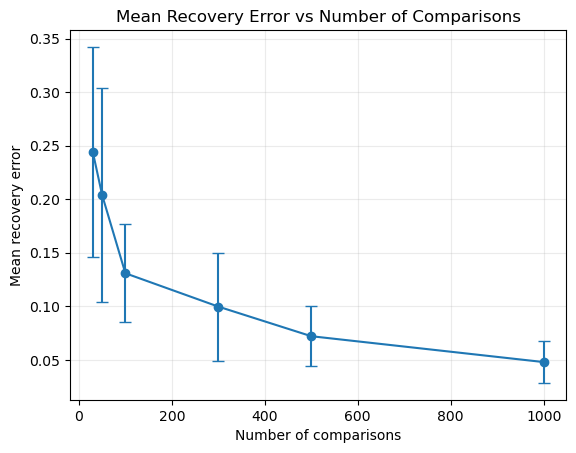

In [46]:
plt.errorbar(comparison_counts,mean_recovery_errors,yerr=std_recovery_errors,marker="o",capsize=4)
plt.xlabel("Number of comparisons")
plt.ylabel("Mean recovery error")
plt.title("Mean Recovery Error vs Number of Comparisons")
plt.grid(alpha=0.25)
plt.show()

Items: 3 Comparisons: 60 Mean error: 0.1513 Standard deviation: 0.094
Items: 5 Comparisons: 100 Mean error: 0.3011 Standard deviation: 0.1139
Items: 10 Comparisons: 200 Mean error: 0.3147 Standard deviation: 0.0644
Items: 20 Comparisons: 400 Mean error: 0.2962 Standard deviation: 0.0399
Items: 50 Comparisons: 1000 Mean error: 0.3147 Standard deviation: 0.0246


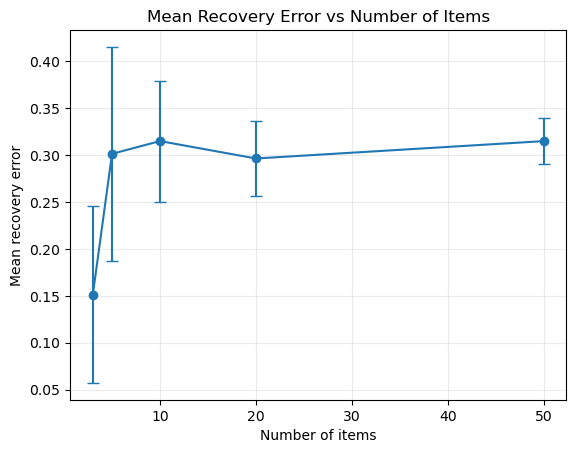

In [ ]:
item_counts=[3,5,10,20,50]
comparisons_per_item=20
mean_item_errors=[]
std_item_errors=[]
start_time=perf_counter()
for current_number_of_items in item_counts:
    current_true_scores=np.linspace(1,-1,current_number_of_items)
    number_of_comparisons=current_number_of_items*comparisons_per_item
    run_errors=[]

    for run in range(number_of_runs):
        run_rng=np.random.default_rng(SEED+run)

        run_winners,run_loosers=generate_comparison_data(
            current_true_scores,
            number_of_comparisons,
            run_rng)

        run_scores,nll_history=estimate_bt_scores(
            current_number_of_items,
            run_winners,
            run_loosers)

        run_error=np.sqrt(np.mean((run_scores-current_true_scores)**2))
        run_errors.append(run_error)

    mean_error=np.mean(run_errors)
    std_error=np.std(run_errors)

    mean_item_errors.append(mean_error)
    std_item_errors.append(std_error)

    print(
        "Items:",current_number_of_items,
        "Comparisons:",number_of_comparisons,
        "Mean error:",round(mean_error,4),
        "Standard deviation:",round(std_error,4)
    )
plt.errorbar(item_counts,mean_item_errors,yerr=std_item_errors,marker="o",capsize=4)
plt.xlabel("Number of items")
plt.ylabel("Mean recovery error")
plt.title("Mean Recovery Error vs Number of Items")
plt.grid(alpha=0.25)
plt.show()

In [49]:
def generate_comparison_data(true_scores,number_of_comparisons,rng,sampling_method="uniform"):
    number_of_items=len(true_scores)
    winners=[]
    loosers=[]
    all_pairs=np.array([
        (item_i,item_j)
        for item_i in range(number_of_items)
        for item_j in range(item_i+1,number_of_items)
    ])
    pair_order=np.arange(len(all_pairs))
    for comparison in range(number_of_comparisons):
        if sampling_method=="uniform":
            item_i,item_j=rng.choice(number_of_items,size=2,replace=False)
        elif sampling_method=="balanced":
            position=comparison%len(all_pairs)
            if position==0:
                pair_order=rng.permutation(len(all_pairs))
            item_i,item_j=all_pairs[pair_order[position]]
        elif sampling_method=="biased":
            if rng.random()<0.8:
                item_i=0
                item_j=rng.choice(np.arange(1,number_of_items))
            else:
                item_i,item_j=rng.choice(number_of_items,size=2,replace=False)
        probability_i_wins=bt_probability(item_i,item_j,true_scores)
        random_number=rng.random()
        if random_number<probability_i_wins:
            winner=item_i
            looser=item_j
        else:
            winner=item_j
            looser=item_i
        winners.append(winner)
        loosers.append(looser)
    return winners,loosers

uniform Mean error: 0.2584 Standard deviation: 0.0506
balanced Mean error: 0.2506 Standard deviation: 0.0594
biased Mean error: 0.2894 Standard deviation: 0.0717


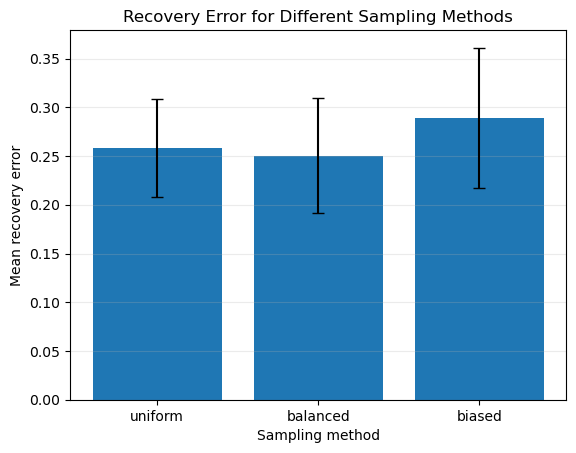

In [51]:
sampling_methods=["uniform","balanced","biased"]
sampling_mean_errors=[]
sampling_std_errors=[]
sampling_number_of_items=10
sampling_number_of_comparisons=300
sampling_true_scores=np.linspace(1,-1,sampling_number_of_items)
for sampling_method in sampling_methods:
    run_errors=[]
    for run in range(number_of_runs):
        run_rng=np.random.default_rng(SEED+run)
        run_winners,run_loosers=generate_comparison_data(
            sampling_true_scores,
            sampling_number_of_comparisons,
            run_rng,
            sampling_method)
        run_scores,nll_history=estimate_bt_scores(
            sampling_number_of_items,
            run_winners,
            run_loosers)
        run_error=np.sqrt(np.mean((run_scores-sampling_true_scores)**2))
        run_errors.append(run_error)
    sampling_mean_errors.append(np.mean(run_errors))
    sampling_std_errors.append(np.std(run_errors))
    print(
        sampling_method,
        "Mean error:",round(np.mean(run_errors),4),
        "Standard deviation:",round(np.std(run_errors),4)
    )
plt.bar(
    sampling_methods,
    sampling_mean_errors,
    yerr=sampling_std_errors,
    capsize=4)

plt.xlabel("Sampling method")
plt.ylabel("Mean recovery error")
plt.title("Recovery Error for Different Sampling Methods")
plt.grid(axis="y",alpha=0.25)
plt.show()